# Singular Value Decomposition for Variance Reduction in Neutronics Simulations


In [1]:
from matplotlib import rcParams
# rcParams.update({
#   "text.usetex": True,
#   "font.family": "serif"
# })

# rcParams['text.latex.preamble'] = r'\usepackage{amssymb} \usepackage{amsmath} \usepackage{amsthm} \usepackage{mathtools}'

import os
path_res = os.path.join(os.getcwd(), 'Results/SVD/')
os.makedirs(path_res, exist_ok=True)

Let us import the data

In [2]:
import numpy as np
from scipy.spatial import cKDTree

# HiFi reference ensemble
_tmp = np.load('Data/flux_data_highstats.npz', allow_pickle=True)
snaps_hs = _tmp['flux']
params_hs = _tmp['params']
centroids_hs = _tmp['centroids']
del _tmp

# LoFi ensemble used in variance-reduction plots (121 MC batches / CR configs)
_tmp = np.load('Data/flux_data_lowstats121.npz', allow_pickle=True)
snaps_121_ls = _tmp['flux']
params_121_ls = _tmp['params']
centroids_121_ls = _tmp['centroids']
del _tmp

# LoFi ensemble used in the main SDN workflow (400 snapshots)
_tmp = np.load('Data/flux_data_lowstats400.npz', allow_pickle=True)
snaps_400_ls = _tmp['flux']
params_400_ls = _tmp['params']
del _tmp

# Match HiFi snapshots to LoFi CR parameters when cardinalities differ
_, hf_idx_400 = cKDTree(params_hs).query(params_400_ls, k=1)
snaps_hs_matched_400 = snaps_hs[:, hf_idx_400]

print('HiFi:', snaps_hs.shape, '| LoFi-121:', snaps_121_ls.shape, '| LoFi-400:', snaps_400_ls.shape)


HiFi: (126750, 121) | LoFi-121: (126750, 121) | LoFi-400: (126750, 400)


Let's calculate the MSE for the low stats data using Frobenius norm

In [3]:
ls_error = np.linalg.norm(snaps_121_ls - snaps_hs, 'fro')
hs_f_norm = np.linalg.norm(snaps_hs, 'fro')

Perform the SVD

In [4]:
from sklearn.utils.extmath import randomized_svd

modes_ls, sing_vals_ls, _ = randomized_svd(snaps_121_ls, n_components=120, n_iter='auto', random_state=None)
modes_hf, sing_vals_hf, _ = randomized_svd(snaps_hs, n_components=120, n_iter='auto', random_state=None)

Let us plot the singular values to see how many modes we need to capture most of the information

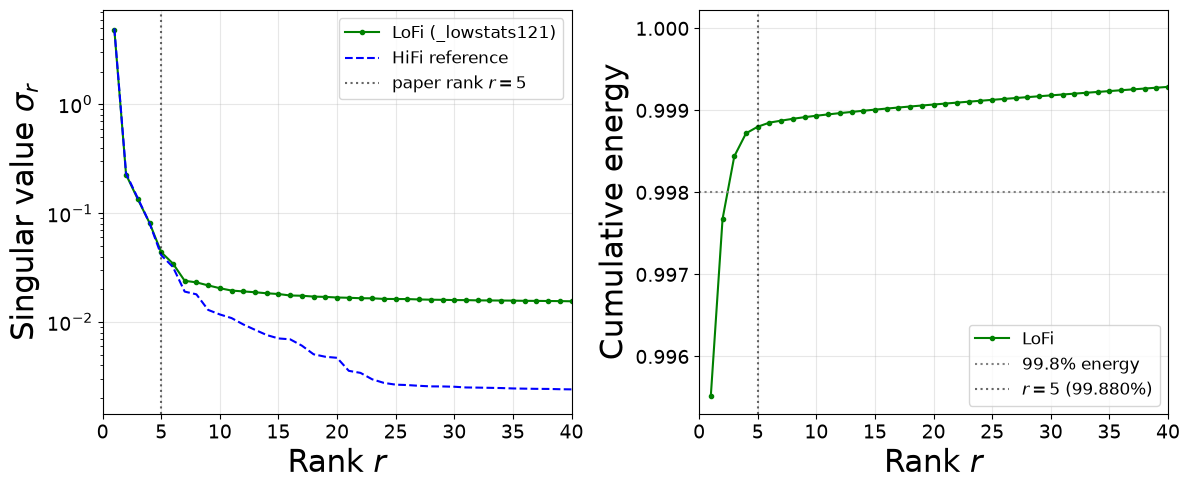

In [5]:
import matplotlib.pyplot as plt

rank_paper = 5
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

ranks = np.arange(1, sing_vals_ls.shape[0] + 1)
axs[0].semilogy(ranks, sing_vals_ls, 'g-o', ms=3, label='LoFi (_lowstats121)')
axs[0].semilogy(ranks, sing_vals_hf, 'b--', ms=3, label='HiFi reference')
axs[0].axvline(rank_paper, color='k', ls=':', alpha=0.6, label=f'paper rank $r={rank_paper}$')
axs[0].set_ylabel('Singular value $\\sigma_r$', fontsize=22)
axs[0].legend(fontsize=12)

cumulative_energy_ls = np.cumsum(sing_vals_ls**2) / np.sum(sing_vals_ls**2)
axs[1].plot(ranks, cumulative_energy_ls, 'g-o', ms=3, label='LoFi')
axs[1].axhline(0.998, color='gray', ls=':', label='99.8% energy')
axs[1].axvline(rank_paper, color='k', ls=':', alpha=0.6, label=f'$r={rank_paper}$ ({cumulative_energy_ls[rank_paper-1]:.3%})')
axs[1].set_ylabel('Cumulative energy', fontsize=22)
axs[1].legend(fontsize=12)

for ax in axs:
    ax.set_xlabel('Rank $r$', fontsize=22)
    ax.set_xlim(0, 40)
    ax.tick_params(labelsize=14)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(path_res, 'singular_values.pdf'), dpi=300, bbox_inches='tight')
plt.show()


## Statistical noise and SVD rank selection

LoFi Monte Carlo flux snapshots are $\mathbf{U}_{LF} = \mathbf{U}_{\mathrm{true}} + \mathbf{E}$, where $\mathbf{E}$ collects cell-wise counting noise. 
Truncated SVD provides an initial **denoising** effect, but modes associated with small singular values can eventually represent MC realizations rather than deterministic spatial structure.

Below we compare several **rank-selection diagnostics** on the LoFi `_lowstats400` ensemble (used in the main SDN workflow; rank $r=5$ in the paper) against the matched HiFi reference. 
The same trends are observed on `_lowstats121`.


### Rank-selection criteria (theory)

**1. Cumulative energy.** For singular values $\sigma_1\ge\sigma_2\ge\cdots$,
$$E(r)=\frac{\sum_{i=1}^{r}\sigma_i^2}{\sum_{i}\sigma_i^2}.$$
In Appendix A we choose $r=5$ because $E(5)\gtrsim 99.8\%$. This measures snapshot **Frobenius energy**, but does not separate deterministic spatial structure from MC noise.

**2. Gavish–Donoho (GD) hard threshold.** For $\mathbf{Y}=\mathbf{X}+\sigma\mathbf{W}$ with i.i.d. $\mathcal{N}(0,1)$ entries in $\mathbf{W}$ and aspect ratio $\beta=\min(m,n)/\max(m,n)$, Gavish & Donoho (2014) define
$$\omega(\beta)=0.56\beta^3-0.95\beta^2+1.82\beta+1.43.$$
The entry-wise noise level $\sigma$ must be mapped to the **singular-value scale** of an $m\times n$ matrix. Empirically (and from random-matrix theory), pure-noise singular values cluster near $\sigma(\sqrt{m}+\sqrt{n})$. We therefore use the snapshot-matrix threshold
$$\lambda^*_{SV}=\omega(\beta)\,\sigma\,(\sqrt{m}+\sqrt{n}),$$
and count signal modes by $\sigma_r>\lambda^*_{SV}$. **Do not** compare $\omega(\beta)\sigma$ directly to $\sigma_r$: that omits the $\mathcal{O}(\sqrt{m}+\sqrt{n})$ scaling and makes $\lambda^*$ appear artificially small.

We estimate $\sigma$ from the entry-wise RMS of $\mathbf{U}_{LF}-\mathbf{U}_{HF}$ at matched CR parameters. Because HiFi snapshots are also MC estimates (lower variance, not zero), this is a **lower bound** on the LoFi-only MC noise $\sigma_{LF}$; using it makes $\lambda^*_{SV}$ slightly conservative (keeps fewer modes).

**3. Marchenko–Pastur (MP) noise ceiling.** For a pure-noise $m\times n$ matrix with i.i.d. $\mathcal{N}(0,\sigma^2)$ entries, the largest singular value is approximately
$$\sigma\,(\sqrt{m}+\sqrt{n}).$$
LoFi singular values persistently above the HiFi tail beyond this ceiling indicate **variance inflation** from MC statistics rather than additional deterministic structure.

**4. Modal Assurance Criterion (MAC).** For matched mode index $r$,
$$\mathrm{MAC}(\boldsymbol{\phi}_r^{LF},\boldsymbol{\phi}_r^{HF})=\frac{|\langle\boldsymbol{\phi}_r^{LF},\boldsymbol{\phi}_r^{HF}\rangle|^2}{\|\boldsymbol{\phi}_r^{LF}\|^2\,\|\boldsymbol{\phi}_r^{HF}\|^2}.$$
Values near 1 indicate coherent spatial structure; a sharp drop signals MC-dominated modes.

**5. HiFi reconstruction error & MC noise floor.** With $\hat{\mathbf{U}}^{(r)}_{LF}=U_rU_r^\top\mathbf{U}_{LF}$,
$$\varepsilon_{HF}(r)=\frac{\|\hat{\mathbf{U}}^{(r)}_{LF}-\mathbf{U}_{HF}\|_F}{\|\mathbf{U}_{HF}\|_F}.$$
Saturation near $\|\mathbf{U}_{LF}-\mathbf{U}_{HF}\|/\|\mathbf{U}_{HF}\|$ marks the MC noise floor.

**6. Variance Reduction Factor (VRF).** $\mathrm{VRF}(r)=\|\mathbf{U}_{LF}-\mathbf{U}_{HF}\|_F/\|\hat{\mathbf{U}}^{(r)}_{LF}-\mathbf{U}_{HF}\|_F$ (evaluated below).


In [7]:
from sklearn.utils.extmath import randomized_svd
import pandas as pd


def gavish_donoho_omega(beta: float) -> float:
    return 0.56 * beta**3 - 0.95 * beta**2 + 1.82 * beta + 1.43


def entrywise_mc_sigma(u_lf, u_hf) -> float:
    """Entry-wise RMS of LF-HiFi discrepancy (lower bound on LoFi MC noise)."""
    m, n = u_lf.shape
    return np.linalg.norm(u_lf - u_hf, 'fro') / np.sqrt(m * n)


def sv_noise_scale(m: int, n: int) -> float:
    """Typical singular-value scale for i.i.d. entry noise on an m x n matrix."""
    return np.sqrt(m) + np.sqrt(n)


def modal_alignment(a, b) -> float:
    return float(np.abs(a.T @ b) / (np.linalg.norm(a) * np.linalg.norm(b)))


def svd_rank_diagnostics(u_lf, u_hf, n_components=80, rank_paper=5, random_state=0):
    """Compute rank-selection metrics for a LoFi/HiFi snapshot pair."""
    m, n = u_lf.shape
    beta = min(m, n) / max(m, n)
    n_sv = min(n_components, min(m, n) - 1)
    sv_scale = sv_noise_scale(m, n)

    modes_lf, s_lf, _ = randomized_svd(u_lf, n_components=n_sv, n_iter='auto', random_state=random_state)
    modes_hf, s_hf, _ = randomized_svd(u_hf, n_components=n_sv, n_iter='auto', random_state=random_state)

    energy = np.cumsum(s_lf**2) / np.sum(s_lf**2)
    sigma_mc = entrywise_mc_sigma(u_lf, u_hf)
    omega = gavish_donoho_omega(beta)

    # Entry-scale (for reporting) vs SV-scale thresholds (for rank counting)
    lambda_gd_entry = omega * sigma_mc
    lambda_gd_sv = omega * sigma_mc * sv_scale
    lambda_mp_sv = sigma_mc * sv_scale

    mac_diag = np.array([modal_alignment(modes_lf[:, i], modes_hf[:, i]) for i in range(n_sv)])
    sv_ratio = s_lf / s_hf

    rank_energy_998 = int(np.searchsorted(energy, 0.998) + 1)
    rank_gd = int(np.sum(s_lf > lambda_gd_sv))
    rank_mp = int(np.sum(s_lf > lambda_mp_sv))
    rank_mac_onset = int(np.where(mac_diag < 0.5)[0][0] + 1) if np.any(mac_diag < 0.5) else n_sv

    err_hf = []
    for r in range(1, n_sv + 1):
        rec = modes_lf[:, :r] @ (modes_lf[:, :r].T @ u_lf)
        err_hf.append(np.linalg.norm(rec - u_hf, 'fro') / np.linalg.norm(u_hf, 'fro'))
    err_hf = np.array(err_hf)
    best_rank_hf = int(np.argmin(err_hf) + 1)
    mc_floor = np.mean(np.linalg.norm(u_lf - u_hf, axis=0) / np.linalg.norm(u_hf, axis=0))

    summary = {
        'n_snapshots': n,
        'energy_at_r5': energy[rank_paper - 1],
        'rank_for_99.8% energy': rank_energy_998,
        'sigma_MC (LF-HF entry RMS)': sigma_mc,
        'lambda_GD entry-scale': lambda_gd_entry,
        'lambda_GD SV-scale': lambda_gd_sv,
        'lambda_MP SV-scale': lambda_mp_sv,
        'r_GD (SV threshold)': rank_gd,
        'r_MP (SV threshold)': rank_mp,
        'r_MAC<0.5': rank_mac_onset,
        'r_best_vs_HiFi': best_rank_hf,
        'MC_noise_floor (mean rel-L2)': mc_floor,
        'min_rel_err_vs_HiFi': err_hf.min(),
    }
    return {
        'summary': summary,
        'modes_lf': modes_lf,
        'modes_hf': modes_hf,
        's_lf': s_lf,
        's_hf': s_hf,
        'energy': energy,
        'mac_diag': mac_diag,
        'sv_ratio': sv_ratio,
        'err_hf': err_hf,
        'lambda_gd_sv': lambda_gd_sv,
        'lambda_mp_sv': lambda_mp_sv,
        'rank_gd': rank_gd,
        'rank_paper': rank_paper,
        'rank_mac_onset': rank_mac_onset,
        'rank_mp': rank_mp,
        'best_rank_hf': best_rank_hf,
        'mc_floor': mc_floor,
        'n_sv': n_sv,
        'sigma_mc': sigma_mc,
    }


diag_400 = svd_rank_diagnostics(snaps_400_ls, snaps_hs_matched_400)
diag_121 = svd_rank_diagnostics(snaps_121_ls, snaps_hs)

summary_df = pd.DataFrame([diag_400['summary'], diag_121['summary']], index=['LoFi-400 (paper)', 'LoFi-121'])
display(summary_df)

print('Note: sigma from LF-HiFi is a lower bound on LoFi-only MC noise (HiFi is also stochastic).')
print(f"LoFi-400 GD rank (SV-scale): r={diag_400['rank_gd']} | MP rank: r={diag_400['rank_mp']} | MAC onset: r={diag_400['rank_mac_onset']}")


,n_snapshots,energy_at_r5,rank_for_99.8% energy,sigma_MC (LF-HF entry RMS),lambda_GD entry-scale,lambda_GD SV-scale,lambda_MP SV-scale,r_GD (SV threshold),r_MP (SV threshold),r_MAC<0.5,r_best_vs_HiFi,MC_noise_floor (mean rel-L2),min_rel_err_vs_HiFi
LoFi-400 (paper),400,0.999618,2,0.000057,0.000082,0.030976,0.021575,8,18,9,8,0.044869,0.031020
LoFi-121,121,0.999149,2,0.000057,0.000081,0.029758,0.020785,6,9,9,8,0.044290,0.031135


Note: sigma from LF-HiFi is a lower bound on LoFi-only MC noise (HiFi is also stochastic).
LoFi-400 GD rank (SV-scale): r=8 | MP rank: r=18 | MAC onset: r=9


<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
<>:42: SyntaxWarning: invalid escape sequence '\p'
<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
<>:42: SyntaxWarning: invalid escape sequence '\p'
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_81702/3024901058.py:16: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('$\sigma_r$')
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_81702/3024901058.py:34: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('$\sigma_r^{LF}/\sigma_r^{HF}$')
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_81702/3024901058.py:42: SyntaxWarning: invalid escape sequence '\p'
  ax.set_ylabel('MAC($\phi_r^{LF},\phi_r^{HF}$)')


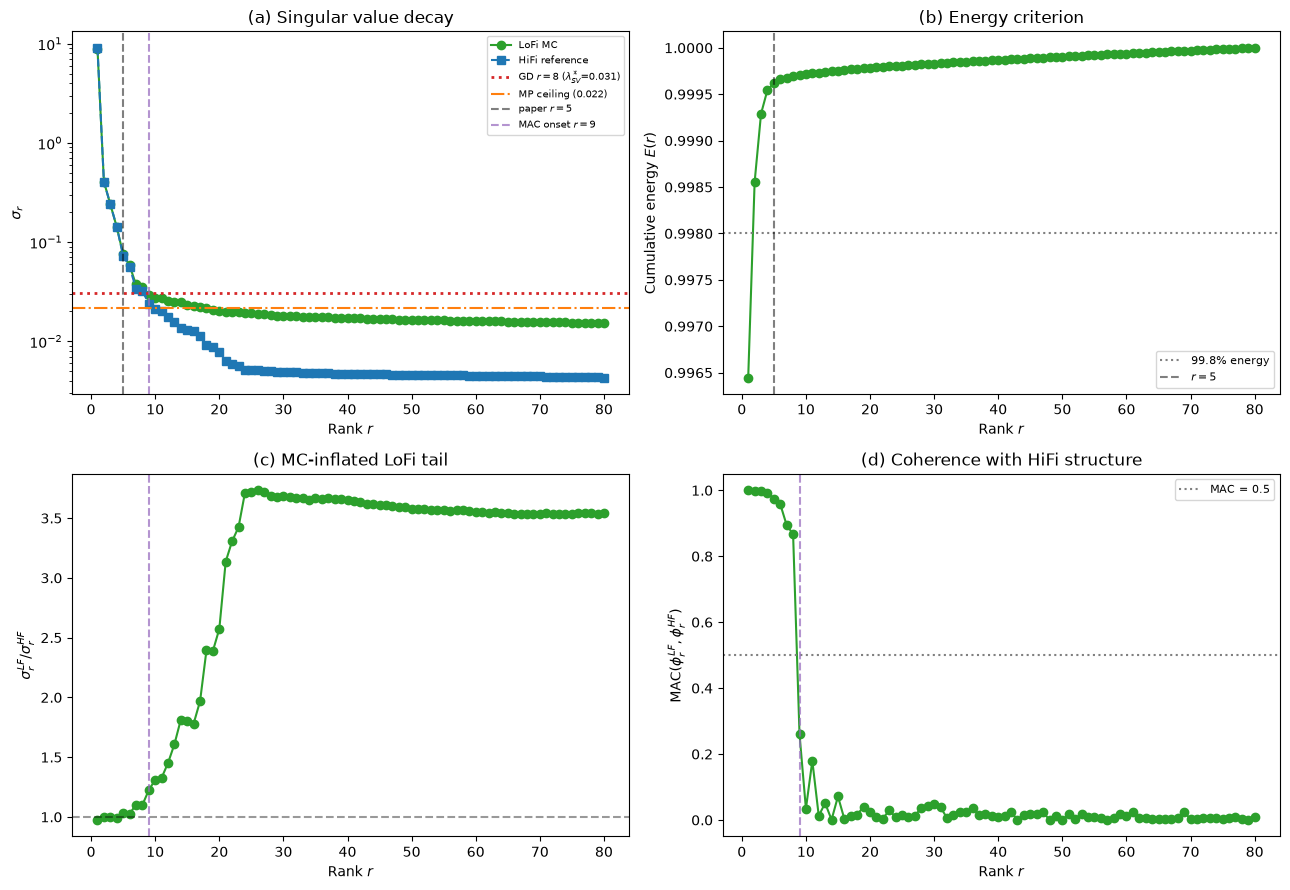

In [8]:
# Four-panel diagnostic figure (LoFi-400, paper dataset)
d = diag_400
ranks = np.arange(1, d['n_sv'] + 1)
rank_paper = d['rank_paper']

fig, axs = plt.subplots(2, 2, figsize=(13, 9))

ax = axs[0, 0]
ax.semilogy(ranks, d['s_lf'], 'o-', label='LoFi MC', color='tab:green')
ax.semilogy(ranks, d['s_hf'], 's--', label='HiFi reference', color='tab:blue')
ax.axhline(d['lambda_gd_sv'], color='tab:red', ls=':', lw=2, label=rf"GD $r={d['rank_gd']}$ ($\lambda^*_{{SV}}$={d['lambda_gd_sv']:.3f})")
ax.axhline(d['lambda_mp_sv'], color='tab:orange', ls='-.', lw=1.5, label=rf"MP ceiling ({d['lambda_mp_sv']:.3f})")
ax.axvline(rank_paper, color='k', ls='--', alpha=0.5, label=f'paper $r={rank_paper}$')
ax.axvline(d['rank_mac_onset'], color='tab:purple', ls='--', alpha=0.7, label=f'MAC onset $r={d["rank_mac_onset"]}$')
ax.set_xlabel('Rank $r$')
ax.set_ylabel('$\sigma_r$')
ax.set_title('(a) Singular value decay')
ax.legend(fontsize=7)

ax = axs[0, 1]
ax.plot(ranks, d['energy'], 'o-', color='tab:green')
ax.axhline(0.998, color='gray', ls=':', label='99.8% energy')
ax.axvline(rank_paper, color='k', ls='--', alpha=0.5, label=f'$r={rank_paper}$')
ax.set_xlabel('Rank $r$')
ax.set_ylabel('Cumulative energy $E(r)$')
ax.set_title('(b) Energy criterion')
ax.legend(fontsize=8)

ax = axs[1, 0]
ax.plot(ranks, d['sv_ratio'], 'o-', color='tab:green')
ax.axhline(1.0, color='k', ls='--', alpha=0.4)
ax.axvline(d['rank_mac_onset'], color='tab:purple', ls='--', alpha=0.7)
ax.set_xlabel('Rank $r$')
ax.set_ylabel('$\sigma_r^{LF}/\sigma_r^{HF}$')
ax.set_title('(c) MC-inflated LoFi tail')

ax = axs[1, 1]
ax.plot(ranks, d['mac_diag'], 'o-', color='tab:green')
ax.axhline(0.5, color='gray', ls=':', label='MAC = 0.5')
ax.axvline(d['rank_mac_onset'], color='tab:purple', ls='--', alpha=0.7)
ax.set_xlabel('Rank $r$')
ax.set_ylabel('MAC($\phi_r^{LF},\phi_r^{HF}$)')
ax.set_ylim(-0.05, 1.05)
ax.set_title('(d) Coherence with HiFi structure')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(path_res, 'svd_noise_rank_diagnostics.pdf'), dpi=300, bbox_inches='tight')
plt.show()


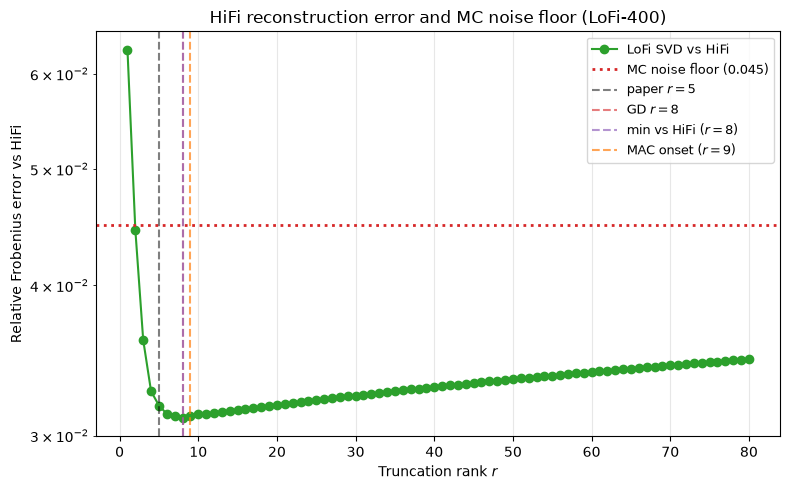

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(ranks, d['err_hf'], 'o-', color='tab:green', label='LoFi SVD vs HiFi')
ax.axhline(d['mc_floor'], color='tab:red', ls=':', lw=2, label=f'MC noise floor ({d["mc_floor"]:.3f})')
ax.axvline(rank_paper, color='k', ls='--', alpha=0.5, label=f'paper $r={rank_paper}$')
ax.axvline(d['rank_gd'], color='tab:red', ls='--', alpha=0.6, label=f'GD $r={d["rank_gd"]}$')
ax.axvline(d['best_rank_hf'], color='tab:purple', ls='--', alpha=0.7, label=f'min vs HiFi ($r={d["best_rank_hf"]}$)')
ax.axvline(d['rank_mac_onset'], color='tab:orange', ls='--', alpha=0.7, label=f'MAC onset ($r={d["rank_mac_onset"]}$)')
ax.set_xlabel('Truncation rank $r$')
ax.set_ylabel('Relative Frobenius error vs HiFi')
ax.set_title('HiFi reconstruction error and MC noise floor (LoFi-400)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(path_res, 'svd_noise_floor_vs_rank.pdf'), dpi=300, bbox_inches='tight')
plt.show()


**Discussion.** For LoFi `_lowstats400` (paper workflow):
- **Energy:** $r=5$ captures $E(5)>99.9\%$ of snapshot energy (Appendix A), but energy alone cannot detect noise modes.
- **Gavish–Donoho (SV-scale):** with $\sigma$ from LF–HiFi and $\lambda^*_{SV}=\omega(\beta)\sigma(\sqrt{m}+\sqrt{n})$, we obtain $r_{GD}\approx 8$–$9$. This aligns with MAC onset ($r\approx 9$) and the best HiFi reconstruction rank ($r\approx 8$). The earlier implementation comparing $\omega(\beta)\sigma$ directly to $\sigma_r$ was **missing the $\sqrt{m}+\sqrt{n}$ scaling** and falsely suggested $r_{GD}\approx 80$.
- **MC noise level:** $\sigma$ from LF–HiFi is a **lower bound** on LoFi-only MC noise because HiFi is also a stochastic MC estimate (lower variance, not zero). Inflating $\sigma$ would raise $\lambda^*_{SV}$ slightly and reduce $r_{GD}$ by one or two modes; it does not change the $\mathcal{O}(10)$ conclusion.
- **MP ceiling:** $\sigma(\sqrt{m}+\sqrt{n})$ gives a more conservative cutoff ($r_{MP}\approx 18$), marking where LoFi tail SVs drop below a pure-noise ceiling.
- **MAC / SV ratio:** modes $1$–$8$ are HiFi-coherent; from $r\approx 9$ onward, MAC collapses and $\sigma_r^{LF}/\sigma_r^{HF}$ inflates.

This supports $r=5$ as a conservative **denoising** choice while noting that ranks $\gtrsim 9$ begin to fit MC-specific fluctuations.


## Variance Reduction Analysis

Criterion **6** above (VRF) is evaluated here on the `_lowstats121` ensemble: can truncated SVD reduce the LoFi–HiFi gap?


At first, let us compute for a given rank $r$
$$
\hat{X}_{LF} = U_{LF}U_{LF}^T X_{LF}
$$
which is the projection of the low stats data onto its own modes. This is the best we can do with the low stats data alone, and it will serve as a baseline for comparison.

Then let us compute the error measured in $L^2$ and $L^\infty$ norms for the low stats data and the SVD reconstruction as a function of the rank $r$.

In [10]:
from tqdm import tqdm

max_rank = 100

err_svd = {
    'L2': np.zeros(max_rank),
    'Linf': np.zeros(max_rank)
}

for rank in tqdm(range(max_rank), desc='Calculating SVD error'):
    # Reconstruct the data using the top 'rank' modes
    U_r = modes_ls[:, :rank]
    X_hat_ls = U_r @ (U_r.T @ snaps_121_ls)

    err_svd['L2'][rank]   = np.linalg.norm(X_hat_ls - snaps_hs, 'fro')
    err_svd['Linf'][rank] = np.linalg.norm(X_hat_ls - snaps_hs, np.inf)

Calculating SVD error: 100%|██████████| 100/100 [00:06<00:00, 15.90it/s]


Let us also compute the error of the LF wrt the HF.

In [11]:
err_lf = {
    'L2': np.linalg.norm(snaps_121_ls - snaps_hs, 'fro'),
    'Linf': np.linalg.norm(snaps_121_ls - snaps_hs, np.inf)
}

vrf = err_lf['L2'] / err_svd['L2']

Let us plot the error as a function of the rank $r$ for both the low stats data and the SVD reconstruction. 

<>:10: SyntaxWarning: invalid escape sequence '\i'
<>:10: SyntaxWarning: invalid escape sequence '\i'
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_81702/1321983483.py:10: SyntaxWarning: invalid escape sequence '\i'
  axs[1].set_ylabel('$L^\infty$ Absolute Error', fontsize=30)


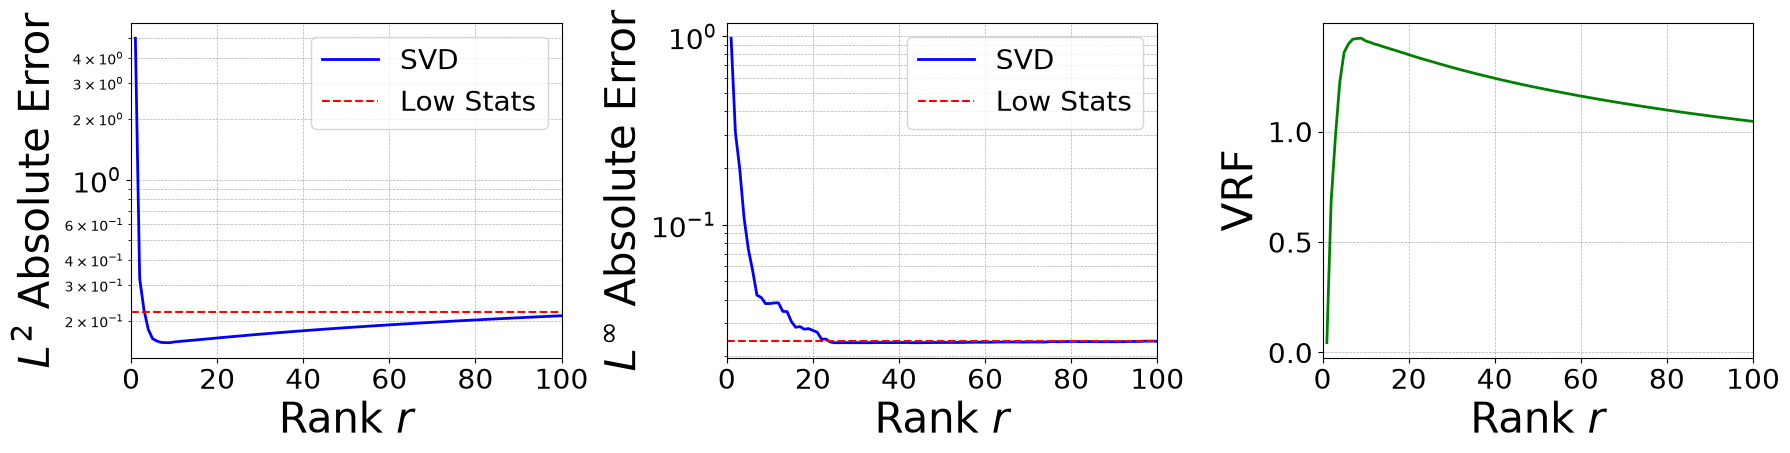

In [12]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(6 * 3, 4.5))

axs[0].semilogy(range(1, max_rank+1), err_svd['L2'], 'b-', label='SVD', linewidth=2)
axs[0].axhline(err_lf['L2'], color='r', linestyle='--', label='Low Stats')
axs[0].set_ylabel('$L^2$ Absolute Error', fontsize=30)

axs[1].semilogy(range(1, max_rank+1), err_svd['Linf'], 'b-', label='SVD', linewidth=2)
axs[1].axhline(err_lf['Linf'], color='r', linestyle='--', label='Low Stats')
axs[1].set_ylabel('$L^\infty$ Absolute Error', fontsize=30)

axs[2].plot(range(1, max_rank+1), vrf, 'g-', label='Variance Reduction Factor', linewidth=2)
axs[2].set_ylabel('VRF', fontsize=30)

for ii, ax in enumerate(axs):
    if ii < 2:  
        ax.legend(fontsize=20)
    ax.tick_params(axis='both', which='major', labelsize=20)
    ax.grid(which='both', linestyle='--', linewidth=0.5)
    ax.set_xlabel('Rank $r$', fontsize=30)
    ax.set_xlim(0, max_rank)

plt.tight_layout()
fig.savefig(os.path.join(path_res, 'svd_error_analysis.pdf'), dpi=300, bbox_inches='tight')

## Comparison of the SVD modes
Since we have also the HF data, we can also compute the SVD modes of the HF data and compare them to the SVD modes of the LF data. This will give us insight into how well the LF data captures the dominant modes of the HF data.

Let us compute the error on the HF data using either the modes from the LF data or the modes from the HF data to see how well the LF modes can reconstruct the HF data compared to the HF modes.

In [13]:
err_svd_lf = np.zeros(max_rank,)
err_svd_hf = np.zeros(max_rank,)

for rr in tqdm(range(max_rank), desc='Calculating SVD reconstruction error'):
    # Reconstruct using LF modes
    U_r_ls = modes_ls[:, :rr]
    X_hat_ls = U_r_ls @ (U_r_ls.T @ snaps_hs)
    err_svd_lf[rr] = np.linalg.norm(X_hat_ls - snaps_hs, 'fro')

    # Reconstruct using HF modes
    U_r_hf = modes_hf[:, :rr]
    X_hat_hf = U_r_hf @ (U_r_hf.T @ snaps_hs)
    err_svd_hf[rr] = np.linalg.norm(X_hat_hf - snaps_hs, 'fro')

Calculating SVD reconstruction error: 100%|██████████| 100/100 [00:06<00:00, 14.78it/s]


Let us compute the full **cross-MAC matrix** between LoFi and HiFi modes (all index pairs). 
The diagonal MAC$_r = \mathrm{MAC}(\phi_r^{LF},\phi_r^{HF})$ used in the rank-selection section above 
measures whether the $r$-th LoFi mode aligns with the corresponding HiFi spatial structure.

$$\text{MAC}(u_i, v_j) = \frac{|\langle u_i, v_j \rangle|^2}{\langle u_i, u_i \rangle \cdot \langle v_j, v_j \rangle}$$

A MAC value close to 1 indicates very similar modes; near 0 indicates near-orthogonality. 
Off-diagonal structure reveals mode mixing when MC noise rotates the LoFi subspace.


In [14]:
mac = np.zeros((max_rank, max_rank))

for ii in range(max_rank):
    for jj in range(max_rank):
        u_i = modes_ls[:, ii]
        v_j = modes_hf[:, jj]
        mac[ii, jj] = np.abs(np.dot(u_i, v_j))**2 / (np.dot(u_i, u_i) * np.dot(v_j, v_j))

Plot the MAC values in a heatmap to visualize the similarity between the modes of the LF and HF data.

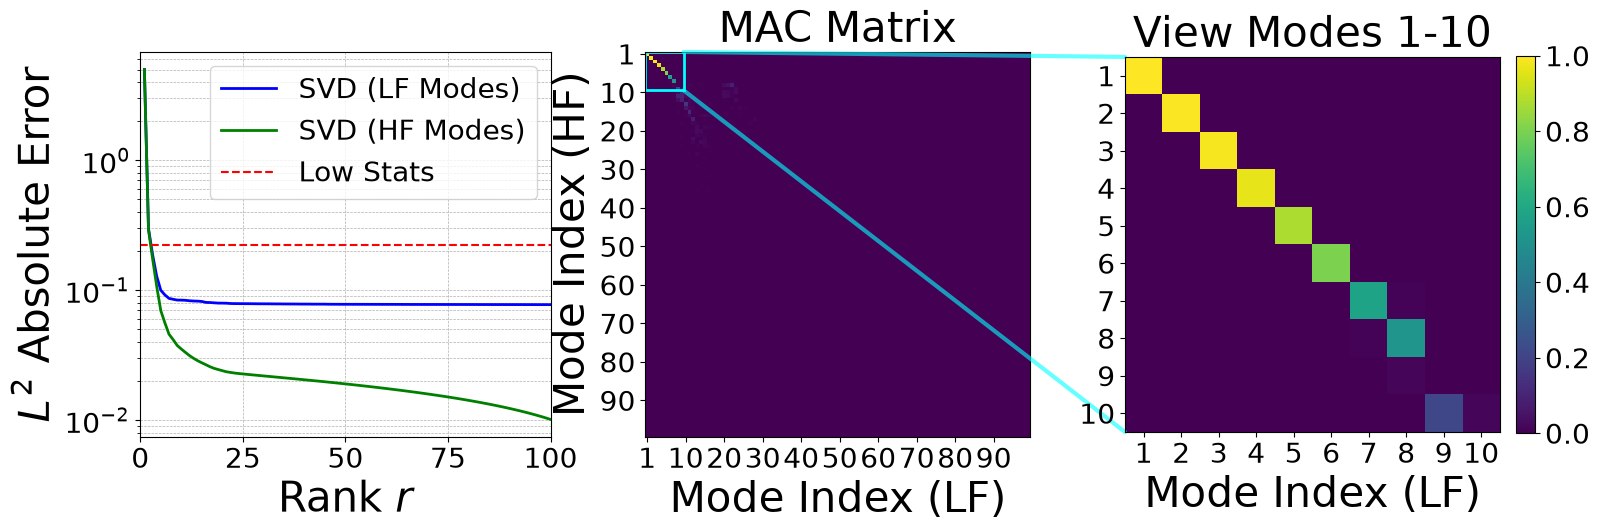

In [15]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import ConnectionPatch

# 1. Setup Data (Assuming mac_matrix is your 100x100 array)
# zoom_range defines the [start, end] for both rows and columns
z_start, z_end = 0, 10 

fig, axs = plt.subplots(1, 3, figsize=(6 * 3, 5))
ax0, ax1, ax2 = axs

# error plot
ax0.semilogy(range(1, max_rank+1), err_svd_lf, 'b-', label='SVD (LF Modes)', linewidth=2)
ax0.semilogy(range(1, max_rank+1), err_svd_hf, 'g-', label='SVD (HF Modes)', linewidth=2)
ax0.axhline(err_lf['L2'], color='r', linestyle='--', label='Low Stats')
ax0.set_xlabel('Rank $r$', fontsize=30)
ax0.set_ylabel('$L^2$ Absolute Error', fontsize=30)
ax0.set_xlim(0, max_rank)
ax0.tick_params(labelsize=20)
ax0.legend(fontsize=20)
ax0.grid(which='both', linestyle='--', linewidth=0.5)
# ax0.axvline(5, color='k', linestyle='--', label='Rank 5')

# 2. Plot Full Matrix (Left)
c = ax1.imshow(mac, cmap='viridis', vmin=0, vmax=1)
ax1.set_title("MAC Matrix", fontsize=30)
ax1.tick_params(labelsize=20)

# Add a highlight rectangle on the full plot
# Rect coords: (x, y), width, height
rect = patches.Rectangle((z_start-0.5, z_start-0.5), z_end-z_start, z_end-z_start, 
                         linewidth=2, edgecolor='cyan', facecolor='none')
ax1.add_patch(rect)

# 3. Plot Zoomed View (Right)
zoom_data = mac[z_start:z_end, z_start:z_end]
ax2.imshow(zoom_data, cmap='viridis', vmin=0, vmax=1)
ax2.set_title(f"View Modes {z_start+1}-{z_end}", fontsize=30)
ax2.tick_params(labelsize=20)

cbar = fig.colorbar(c, ax=ax2, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=20)

# 4. Correct Connection Patches
# Connect the top-right of the rectangle (ax1) to top-left of the zoom (ax2)
# and bottom-right of the rectangle (ax1) to bottom-left of the zoom (ax2)
con1 = ConnectionPatch(xyA=(z_end-0.5, z_start-0.5), xyB=(-0.5, -0.5), 
                        coordsA="data", coordsB="data", lw=3,
                        axesA=ax1, axesB=ax2, color="cyan", alpha=0.6)

con2 = ConnectionPatch(xyA=(z_end-0.5, z_end-0.5), xyB=(-0.5, z_end-z_start-0.5), 
                        coordsA="data", coordsB="data", lw=3,
                        axesA=ax1, axesB=ax2, color="cyan", alpha=0.6)

ax2.add_artist(con1)
ax2.add_artist(con2)

for ax in axs[1:]:
    ax.set_xlabel('Mode Index (LF)', fontsize=30)

ax1.set_ylabel('Mode Index (HF)', fontsize=30)

# Set ticks and labels for the full matrix plot
axs[1].set_xticks(np.arange(0, max_rank, 10))
axs[1].set_xticklabels(np.concatenate([[1], np.arange(10, max_rank, 10)]))
axs[1].set_yticks(np.arange(0, max_rank, 10))
axs[1].set_yticklabels(np.concatenate([[1], np.arange(10, max_rank, 10)]))

# Set ticks and labels for the zoomed plot
axs[2].set_xticks(np.arange(0, z_end-z_start, 1))
axs[2].set_xticklabels(np.arange(z_start+1, z_end+1))
axs[2].set_yticks(np.arange(0, z_end-z_start, 1))
axs[2].set_yticklabels(np.arange(z_start+1, z_end+1))

fig.savefig(os.path.join(path_res, 'comparison_svd_modes.pdf'), dpi=300, bbox_inches='tight')

Let us compare the Subspace angles between the LF and HF modes.

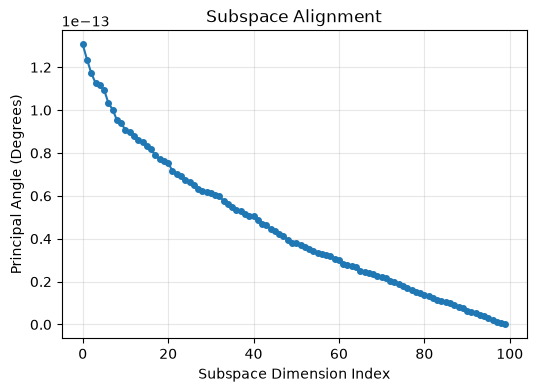

In [16]:
from scipy.linalg import subspace_angles

sub_angles = subspace_angles(modes_ls[:, :max_rank].T, modes_hf[:, :max_rank].T)

angles_deg = np.degrees(sub_angles)

plt.figure(figsize=(6, 4))
plt.plot(angles_deg, 'o-', markersize=4)
# plt.axhline(y=90, color='r', linestyle='--', label='Orthogonal')
plt.ylabel("Principal Angle (Degrees)")
plt.xlabel("Subspace Dimension Index")
plt.grid(True, alpha=0.3)
plt.title("Subspace Alignment")
plt.show()

In the end, let us compute the error on the HF data using either the modes from the LF data or the modes from the HF data to see how well the LF modes can reconstruct the HF data compared to the HF modes.

Let us plot the error as a function of the rank $r$ for both the low stats data and the SVD reconstruction.

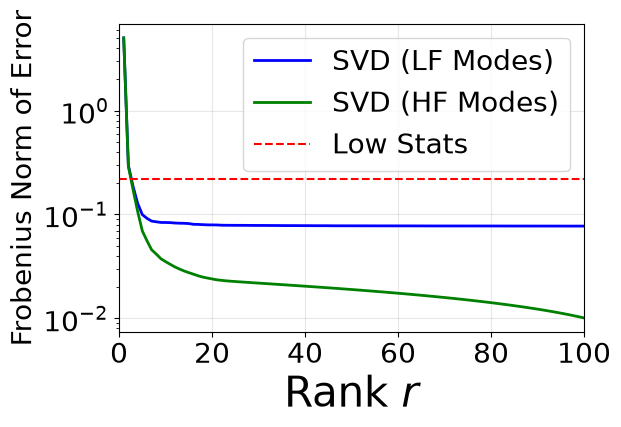

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(range(1, max_rank+1), err_svd_lf, 'b-', label='SVD (LF Modes)', linewidth=2)
ax.semilogy(range(1, max_rank+1), err_svd_hf, 'g-', label='SVD (HF Modes)', linewidth=2)
ax.axhline(err_lf['L2'], color='r', linestyle='--', label='Low Stats')
ax.set_xlabel('Rank $r$', fontsize=30)
ax.set_ylabel('Frobenius Norm of Error', fontsize=20)
ax.set_xlim(0, max_rank)
ax.tick_params(labelsize=20)
ax.legend(fontsize=20)
ax.grid(True, alpha=0.3)